# 23CSE301 Machine Learning — Capstone Project
## Classification Track — Review 2 (Part A + Part B, all 10 algorithms)

**Team:** TASKMASTERS (Team 16)
**Dataset:** Australian Open Men's Singles Matches (2008–2022), SCORE Network
**Target:** `higher_rank_won` — did the higher-ranked player (the favourite) win the match?

---

### Problem statement

We predict whether the favourite wins a match using only information known **before** the match starts: both players' rankings, experience, height, weight and handedness. This is a binary classification problem. The target is imbalanced, because favourites win about 3 out of 4 matches.

### Review 2 scope (rubric section 6)

| Rubric item | Where it is covered |
|---|---|
| A1 — Part-B algorithms on the same dataset as Part A | Sections 5 and 6 (same data, same features, same split) |
| A2 — Single 10-algorithm comparison table | Section 7 |
| A3 — Final model selection, tuning, documented improvement | Section 9 |
| C1 — Clean notebook, modular functions, commented code | Helper functions in Section 4; every cell runs top-to-bottom |

### Notebook flow

**Load & audit → EDA → Leakage-aware feature engineering → Stratified split → Pipelines (fit on train only) → 10 classifiers → Comparison table → Confusion matrices & ROC → Cross-validation → Final model selection & tuning → Conclusions**

### Classification model reference

| # | Part | Algorithm | Core idea | Hyperparameters tuned |
|---:|:---:|---|---|---|
| 1 | A | **Logistic Regression** | Linear model of the log-odds through a sigmoid | `C` |
| 2 | A | **K-Nearest Neighbors** | Majority vote of the `k` closest training matches | `n_neighbors`, `metric` |
| 3 | A | **Gaussian Naive Bayes** | Bayes' theorem with conditionally independent Gaussian features | `var_smoothing` |
| 4 | A | **Decision Tree** | Recursive if/then splits on impurity | `max_depth`, `min_samples_leaf`, `criterion` |
| 5 | A | **Support Vector Machine** | Maximum-margin boundary, kernels for non-linearity | `C`, `kernel` |
| 6 | B | **Random Forest** | Bagged decision trees with random feature subsets | `n_estimators`, `max_depth` |
| 7 | B | **AdaBoost** | Sequentially re-weights misclassified samples | `n_estimators`, `learning_rate` |
| 8 | B | **Gradient Boosting** | Sequential trees fitted to the loss gradient | `n_estimators`, `learning_rate`, `max_depth` |
| 9 | B | **Bagging** | Bootstrap-aggregated Decision Trees | `n_estimators`, `max_samples` |
| 10 | B | **MLP (Neural Network)** | Feed-forward network trained by back-propagation | `hidden_layer_sizes`, `activation` |

**Evaluation metrics (all mandatory):** Accuracy, weighted Precision, weighted Recall, weighted F1, ROC-AUC and the confusion matrix.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold, cross_validate
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)

# Part A algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC

# Part B algorithms
from sklearn.ensemble import (
    RandomForestClassifier, AdaBoostClassifier,
    GradientBoostingClassifier, BaggingClassifier
)
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")

print("Libraries imported. Random state:", RANDOM_STATE)

Libraries imported. Random state: 42


## 1. Dataset loading and audit

The audit reports shape, data types, missing values, duplicates and the class distribution before any modelling.

In [2]:
df = pd.read_csv("AustralianOpen.csv", encoding="latin1")

print("Shape:", df.shape)
display(df.head())

Shape: (1905, 19)


,Year,Winner,Loser,WRank,LRank,pl1_flag,pl1_year_pro,pl1_weight,pl1_height,pl1_hand,pl2_flag,pl2_year_pro,pl2_weight,pl2_height,pl2_hand,higher_rank_won,rank_diff,rank_diff_cat,same_handedness
0,2022,Shapovalov D.,Djere L.,14,51.0,CAN,2016,76,183,Left,SRB,2013.0,80.0,185.0,Right,Yes,-37.0,Medium,No
1,2022,Kwon S.W.,Rune H.,54,99.0,KOR,2015,72,180,Right,DEN,2020.0,77.0,188.0,Right,Yes,-45.0,Medium,Yes
2,2022,Lajovic D.,Fucsovics M.,39,35.0,SRB,2007,78,183,Right,HUN,2010.0,82.0,188.0,Right,No,4.0,Low,Yes
3,2022,Vukic A.,Harris L.,144,33.0,AUS,2018,85,188,Right,RSA,2015.0,80.0,193.0,Right,No,111.0,High,Yes
4,2022,Garin C.,Bagnis F.,19,72.0,CHI,2013,85,185,Right,ARG,2008.0,82.0,183.0,Left,Yes,-53.0,Medium,No


In [3]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
})
display(audit)

print("Duplicate rows:", df.duplicated().sum())

print("\nTarget distribution (higher_rank_won):")
target_summary = pd.DataFrame({
    "count": df["higher_rank_won"].value_counts(dropna=False),
    "share_%": (df["higher_rank_won"].value_counts(normalize=True, dropna=False) * 100).round(2),
})
display(target_summary)

,dtype,missing,missing_%
Year,int64,0,0.00
Winner,str,0,0.00
Loser,str,0,0.00
WRank,int64,0,0.00
LRank,float64,6,0.31
pl1_flag,str,0,0.00
pl1_year_pro,int64,0,0.00
pl1_weight,int64,0,0.00
pl1_height,int64,0,0.00
pl1_hand,str,0,0.00


Duplicate rows: 0

Target distribution (higher_rank_won):


,count,share_%
higher_rank_won,,
Yes,1413,74.17
No,486,25.51
NaN,6,0.31


**Audit observations.**
- 1,905 matches and 19 columns, with no duplicate rows.
- `LRank` and the target `higher_rank_won` are missing for the same 6 matches. The target cannot be computed for them, so those rows are dropped.
- 29 matches have no player-2 profile (`pl2_year_pro`, `pl2_height`, `pl2_weight`, `same_handedness`). Instead of deleting them, we impute these values with the **training-set median** inside the pipeline.
- The target is imbalanced: favourites win about **74%** of matches. A model that always predicts "Yes" already reaches about 0.74 accuracy, so weighted F1 and ROC-AUC tell us more than accuracy alone.

## 2. Exploratory data analysis

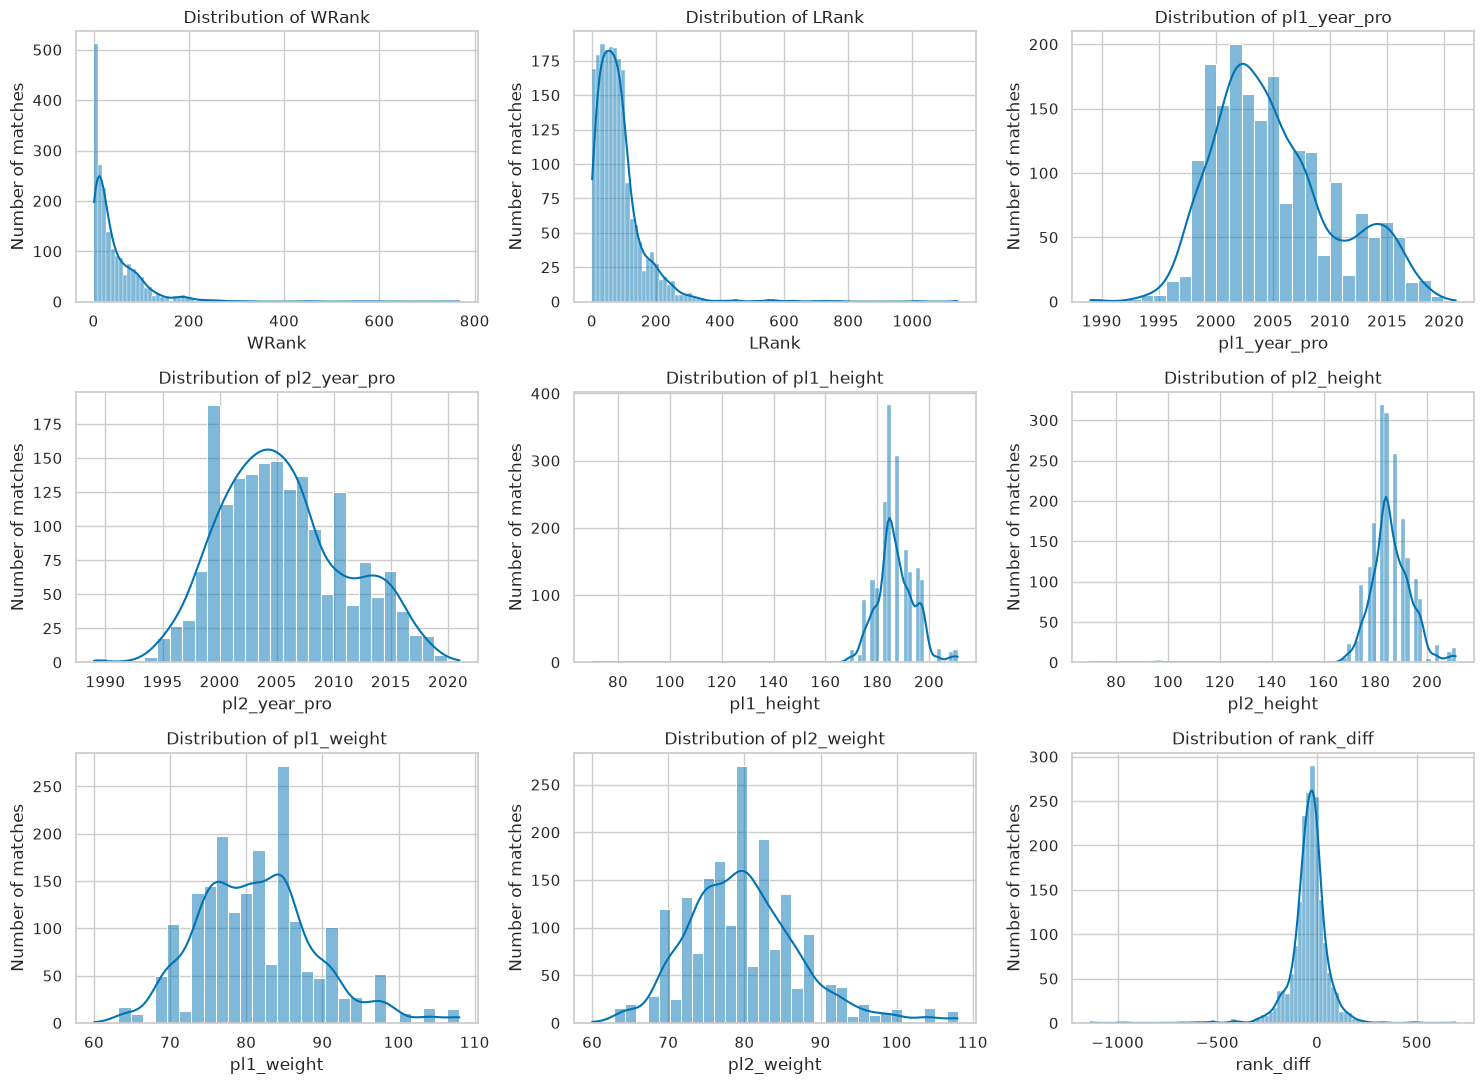

In [4]:
eda_features = [
    "WRank", "LRank", "pl1_year_pro", "pl2_year_pro",
    "pl1_height", "pl2_height", "pl1_weight", "pl2_weight", "rank_diff"
]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, column in zip(axes.ravel(), eda_features):
    sns.histplot(df[column].dropna(), kde=True, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of matches")
plt.tight_layout()
plt.show()

**Distribution observations.** Rankings (`WRank`, `LRank`) are strongly right-skewed. Most players are inside the top 100, but a few qualifiers and wild cards are ranked several hundred places lower. Height, weight and turning-pro year are roughly bell-shaped. The skew in rankings is why Section 3 adds a **log-ratio** rank feature.

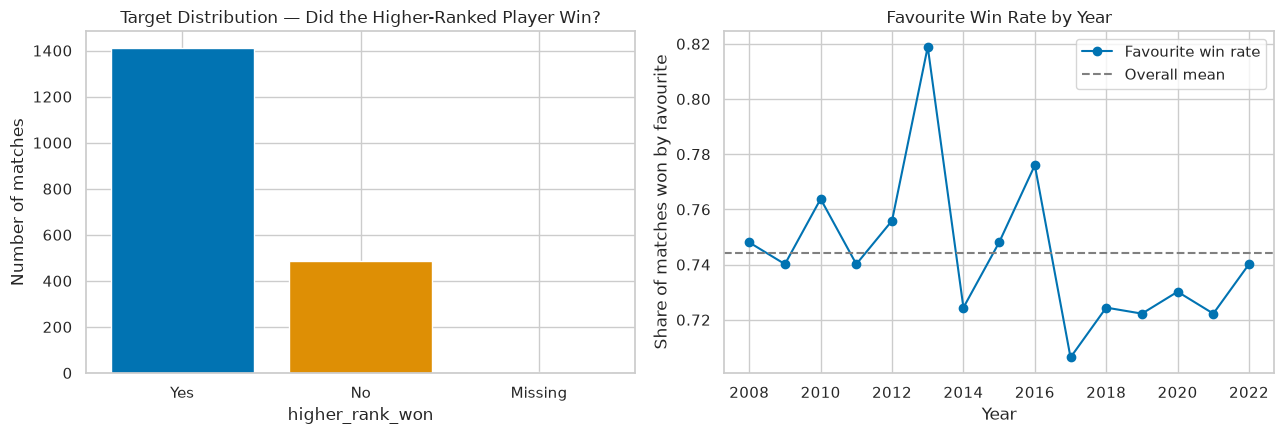

In [5]:
counts = df["higher_rank_won"].fillna("Missing").value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(counts.index, counts.values, color=sns.color_palette("colorblind")[:len(counts)])
axes[0].set_title("Target Distribution — Did the Higher-Ranked Player Win?")
axes[0].set_xlabel("higher_rank_won")
axes[0].set_ylabel("Number of matches")

year_rate = (
    df.dropna(subset=["higher_rank_won"])
    .assign(fav_won=lambda d: d["higher_rank_won"].eq("Yes"))
    .groupby("Year")["fav_won"].mean()
)
axes[1].plot(year_rate.index, year_rate.values, marker="o", label="Favourite win rate")
axes[1].axhline(year_rate.mean(), linestyle="--", color="grey", label="Overall mean")
axes[1].set_title("Favourite Win Rate by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Share of matches won by favourite")
axes[1].legend()
plt.tight_layout()
plt.show()

**Target observations.** The favourite wins about three quarters of matches, and this rate stays fairly stable from 2008 to 2022. The year is therefore not used as a predictor. Because the classes are imbalanced, we use a **stratified** train/test split.

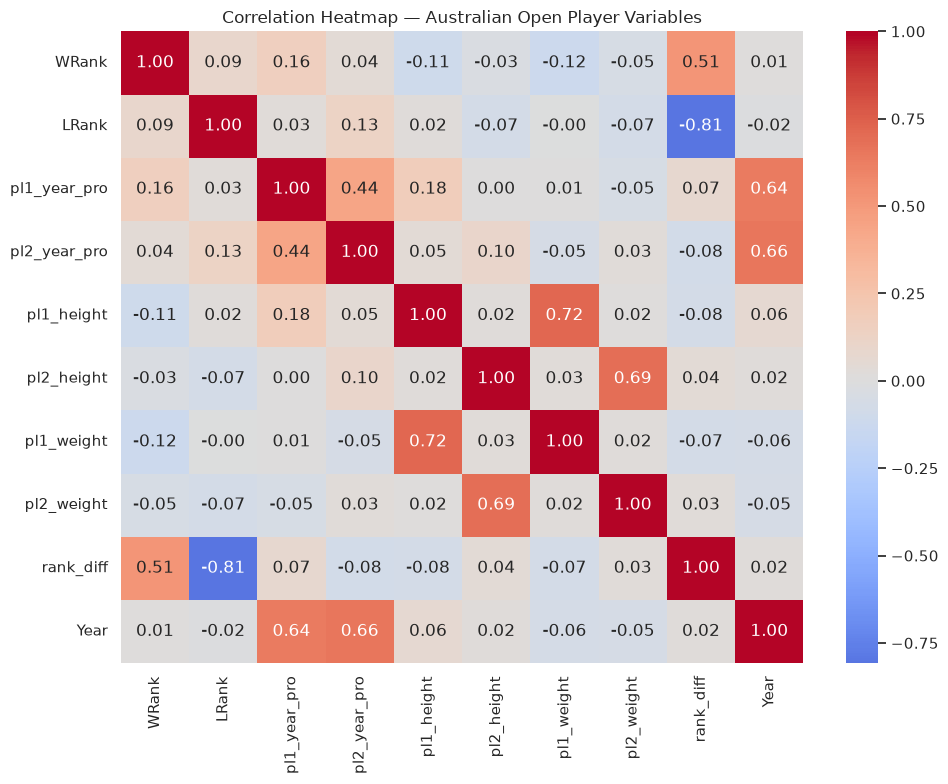

In [6]:
corr_cols = eda_features + ["Year"]

plt.figure(figsize=(10, 8))
sns.heatmap(df[corr_cols].corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — Australian Open Player Variables")
plt.tight_layout()
plt.show()

**Correlation observations.**
- Each player's height and weight are strongly correlated.
- `rank_diff` is almost a linear function of `WRank` and `LRank`.
- `WRank`, `LRank` and `rank_diff` are recorded from the **winner's** point of view, so their sign gives away the answer: if `WRank < LRank`, the favourite won. Using them directly would be **target leakage**, so Section 3 rebuilds every feature to be symmetric in the two players.

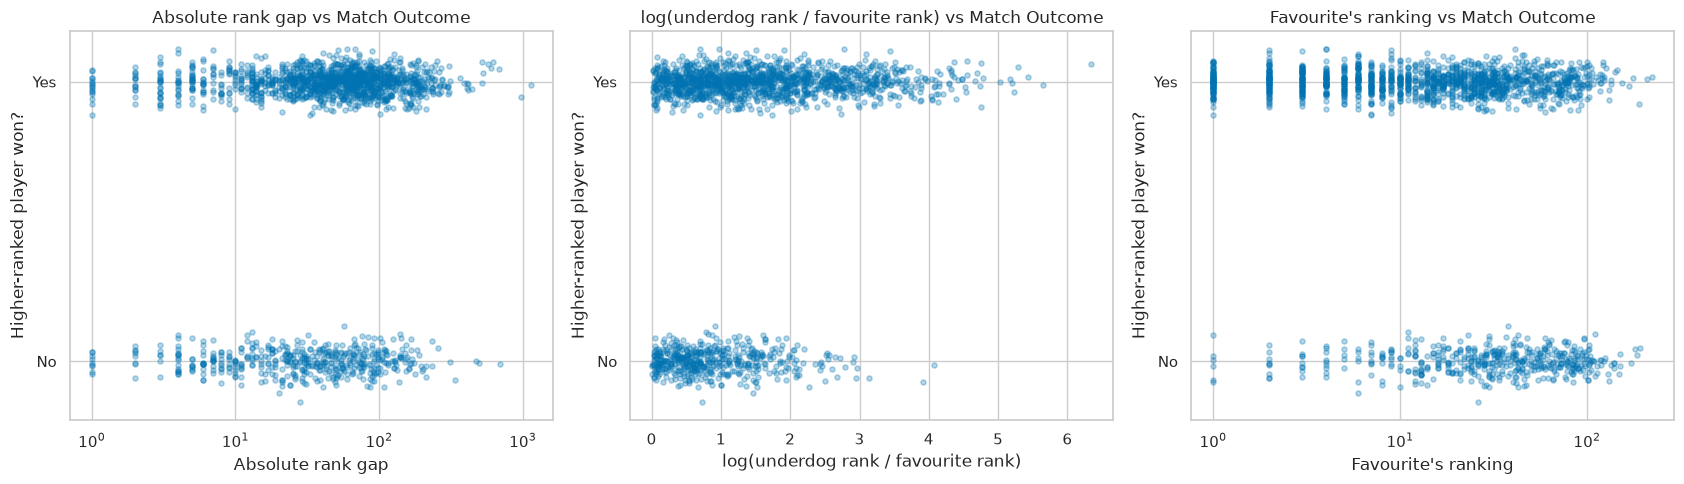

In [7]:
plot_df = df.dropna(subset=["higher_rank_won"]).copy()
plot_df["fav_rank"] = np.minimum(plot_df["WRank"], plot_df["LRank"])
plot_df["rank_gap_abs"] = (plot_df["WRank"] - plot_df["LRank"]).abs()
plot_df["log_rank_ratio"] = np.log(np.maximum(plot_df["WRank"], plot_df["LRank"]) / plot_df["fav_rank"])

rng = np.random.default_rng(RANDOM_STATE)
plot_df["target_jitter"] = plot_df["higher_rank_won"].eq("Yes").astype(int) + rng.normal(0, 0.04, len(plot_df))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, column, label in zip(
    axes,
    ["rank_gap_abs", "log_rank_ratio", "fav_rank"],
    ["Absolute rank gap", "log(underdog rank / favourite rank)", "Favourite's ranking"],
):
    ax.scatter(plot_df[column], plot_df["target_jitter"], alpha=0.3, s=14)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["No", "Yes"])
    ax.set_title(f"{label} vs Match Outcome")
    ax.set_xlabel(label)
    ax.set_ylabel("Higher-ranked player won?")
axes[0].set_xscale("log")
axes[2].set_xscale("log")
plt.tight_layout()
plt.show()

**Feature-target observations.**
- The "No" band (upsets) thins out as the rank gap and the log rank ratio grow.
- Upsets are more common when the favourite is ranked outside the top 20 or so.

So both the *relative* gap between the players and the favourite's *own* level carry signal. The engineered features below build on this.

## 3. Preprocessing and feature engineering

### 3.1 Data cleaning

In [8]:
working_df = df.dropna(subset=["higher_rank_won"]).copy()
print("Rows after removing matches with no target:", len(working_df))

# Symmetric (winner/loser-agnostic) features
favourite_rank = np.minimum(working_df["WRank"], working_df["LRank"])
underdog_rank = np.maximum(working_df["WRank"], working_df["LRank"])

working_df["rank_gap_abs"] = underdog_rank - favourite_rank
working_df["experience_gap_abs"] = (working_df["pl1_year_pro"] - working_df["pl2_year_pro"]).abs()
working_df["height_gap_abs"] = (working_df["pl1_height"] - working_df["pl2_height"]).abs()
working_df["weight_gap_abs"] = (working_df["pl1_weight"] - working_df["pl2_weight"]).abs()
working_df["same_handedness_bin"] = working_df["same_handedness"].map({"Yes": 1, "No": 0})

# Review 2 engineered features
working_df["fav_rank"] = favourite_rank
working_df["log_rank_ratio"] = np.log(underdog_rank / favourite_rank)

working_df["target"] = working_df["higher_rank_won"].map({"No": 0, "Yes": 1}).astype(int)


def iqr_outlier_count(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum())


outlier_features = ["rank_gap_abs", "experience_gap_abs", "height_gap_abs",
                    "weight_gap_abs", "fav_rank", "log_rank_ratio"]
display(pd.DataFrame({
    "IQR outliers": {c: iqr_outlier_count(working_df[c].dropna()) for c in outlier_features},
    "missing": working_df[outlier_features].isna().sum(),
}))

Rows after removing matches with no target: 1899


,IQR outliers,missing
rank_gap_abs,113,0
experience_gap_abs,21,28
height_gap_abs,51,28
weight_gap_abs,55,28
fav_rank,91,0
log_rank_ratio,31,0


**Cleaning decisions and justification.**
- **Missing target (6 rows):** dropped, because a label cannot be imputed.
- **Missing player-2 attributes (29 rows):** kept and imputed with the training median inside the pipeline. The median is robust to the skewed gaps.
- **Duplicates:** none found.
- **Outliers:** the IQR rule flags large rank gaps and highly ranked favourites. These are *real* matches (for example a top-5 seed against a qualifier), and they are exactly the cases the model needs to learn, so we **keep** them. The log transform in `log_rank_ratio` reduces their influence instead.

### 3.2 Feature engineering

| Feature | Review | Definition | Why it helps |
|---|:---:|---|---|
| `rank_gap_abs` | 1 | \|WRank − LRank\| | Larger gap → stronger favourite |
| `experience_gap_abs` | 1 | \|pl1_year_pro − pl2_year_pro\| | Experience mismatch |
| `height_gap_abs`, `weight_gap_abs` | 1 | absolute physical differences | Physical mismatch |
| `same_handedness_bin` | 1 | 1 if both players share a dominant hand | Left-handers create unusual angles |
| `fav_rank` | **2** | min(WRank, LRank) | A gap of 50 places means more between #1 and #51 than between #150 and #200 |
| `log_rank_ratio` | **2** | log(underdog rank / favourite rank) | Scale-free strength ratio; tames the heavy right skew |

Every feature is computed from the *pair* of players, never from who won, so there is **no target leakage**. The Part A models are re-trained on this same feature set so that the 10-algorithm comparison is fair. Section 9.2 measures how much the two new features help.

In [9]:
REVIEW1_FEATURES = ["rank_gap_abs", "experience_gap_abs", "height_gap_abs",
                    "weight_gap_abs", "same_handedness_bin"]
FEATURES = REVIEW1_FEATURES + ["fav_rank", "log_rank_ratio"]

X = working_df[FEATURES]
y = working_df["target"]

print("Modelling matrix:", X.shape)
display(y.value_counts().rename(index={1: "Yes (favourite won)", 0: "No (upset)"}).to_frame("count"))

Modelling matrix: (1899, 7)


,count
target,
Yes (favourite won),1413
No (upset),486


### 3.3 Stratified train/test split and leakage-free preprocessing

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
display(pd.DataFrame({
    "train share": y_train.value_counts(normalize=True).round(3),
    "test share": y_test.value_counts(normalize=True).round(3),
}))


def make_preprocessor(features):
    # Median imputation + standard scaling; both are fitted on the training fold only
    # because they live inside the model Pipeline.
    return ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), features)
    ])

X_train: (1519, 7) | X_test: (380, 7)


,train share,test share
target,,
1,0.744,0.745
0,0.256,0.255


The imputer and scaler sit inside a `Pipeline` together with each classifier. This means `GridSearchCV` and `cross_validate` re-fit them on each training fold only, and the test set is only ever *transformed*. That meets the guideline that "scalers and encoders must be fitted on the training set only".

## 4. Shared training and evaluation helpers

All ten algorithms go through the same two functions, so every model is tuned, evaluated and stored in the same way.

In [11]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
TUNING_METRIC = "f1_weighted"   # same tuning metric as Review 1

results = {}        # model name -> metric dict
fitted_models = {}  # model name -> fitted best pipeline
predictions = {}    # model name -> (y_pred, y_prob)


def compute_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
    }


def train_and_evaluate(name, part, estimator, param_grid, features=FEATURES):
    # Tune on the training set with 5-fold CV, then score the best pipeline on the held-out test set.
    pipeline = Pipeline([("preprocess", make_preprocessor(features)), ("model", estimator)])
    grid = GridSearchCV(pipeline, param_grid, cv=CV, scoring=TUNING_METRIC, n_jobs=-1)
    grid.fit(X_train[features], y_train)

    best = grid.best_estimator_
    y_pred = best.predict(X_test[features])
    y_prob = best.predict_proba(X_test[features])[:, 1]

    metrics = compute_metrics(y_test, y_pred, y_prob)
    results[name] = {"Part": part, **metrics, "Best params": grid.best_params_}
    fitted_models[name] = best
    predictions[name] = (y_pred, y_prob)

    print(f"{name} — best parameters: {grid.best_params_}")
    print(f"CV {TUNING_METRIC}: {grid.best_score_:.4f}")
    display(pd.DataFrame([metrics], index=[name]).round(4))
    return best

## 5. Classification Part A (Review 1 algorithms, re-run on the final feature set)

### Algorithm 1 — Logistic Regression
This is the baseline linear classifier. After fitting, we convert the coefficients to **odds ratios** (`exp(coef)`) to interpret them.

In [12]:
logreg = train_and_evaluate(
    "Logistic Regression", "A",
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    {"model__C": [0.01, 0.1, 1, 10, 100]},
)

odds = pd.DataFrame({
    "coefficient (per 1 SD)": logreg.named_steps["model"].coef_[0],
    "odds ratio": np.exp(logreg.named_steps["model"].coef_[0]),
}, index=FEATURES).sort_values("coefficient (per 1 SD)")
display(odds.round(3))

Logistic Regression — best parameters: {'model__C': 0.1}
CV f1_weighted: 0.6566


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.7526,0.7434,0.7526,0.6626,0.7046


,coefficient (per 1 SD),odds ratio
fav_rank,-0.096,0.909
rank_gap_abs,-0.092,0.912
experience_gap_abs,-0.090,0.914
weight_gap_abs,-0.055,0.947
height_gap_abs,-0.030,0.970
same_handedness_bin,0.023,1.023
log_rank_ratio,0.873,2.395


**Interpretation.** Each odds ratio is for a one-standard-deviation increase in a scaled feature. A value above 1 raises the odds that the favourite wins, and a value below 1 lowers them.
- `log_rank_ratio` has by far the largest effect (OR ≈ 2.4): the bigger the strength ratio, the safer the favourite.
- A higher `fav_rank` number, meaning a weaker favourite, lowers the odds.

### Algorithm 2 — K-Nearest Neighbors
KNN is distance-based, so scaling is essential. We tune `k` and compare Euclidean with Manhattan distance.

In [13]:
knn = train_and_evaluate(
    "K-Nearest Neighbors", "A",
    KNeighborsClassifier(),
    {"model__n_neighbors": [5, 11, 21, 31, 41, 51], "model__metric": ["euclidean", "manhattan"]},
)

K-Nearest Neighbors — best parameters: {'model__metric': 'manhattan', 'model__n_neighbors': 5}
CV f1_weighted: 0.6972


,Accuracy,Precision,Recall,F1,ROC-AUC
K-Nearest Neighbors,0.6947,0.6351,0.6947,0.6541,0.6002


Cross-validation picks `k = 5` with **Manhattan** distance. Manhattan distance is less affected than Euclidean by a single large difference, such as a huge rank gap. KNN is still the weakest model here: with seven features and a noisy outcome, a match's nearest neighbours are often not truly similar matches.

### Algorithm 3 — Gaussian Naive Bayes
Naive Bayes assumes that features are **conditionally independent given the class**. That assumption does not hold here, because `rank_gap_abs`, `fav_rank` and `log_rank_ratio` all come from the same two rankings. Naive Bayes therefore counts the ranking evidence more than once, which makes it a useful contrast with the other models.

In [14]:
gnb = train_and_evaluate(
    "Gaussian Naive Bayes", "A",
    GaussianNB(),
    {"model__var_smoothing": np.logspace(-9, -1, 9)},
)

Gaussian Naive Bayes — best parameters: {'model__var_smoothing': np.float64(0.01)}
CV f1_weighted: 0.6884


,Accuracy,Precision,Recall,F1,ROC-AUC
Gaussian Naive Bayes,0.7368,0.7232,0.7368,0.7286,0.6961


### Algorithm 4 — Decision Tree
We tune `max_depth` (the main control on over-fitting), the split criterion and the minimum leaf size, then plot the top of the tree.

Decision Tree — best parameters: {'model__criterion': 'entropy', 'model__max_depth': 7, 'model__min_samples_leaf': 20}
CV f1_weighted: 0.6852


,Accuracy,Precision,Recall,F1,ROC-AUC
Decision Tree,0.7395,0.6649,0.7395,0.6549,0.6652


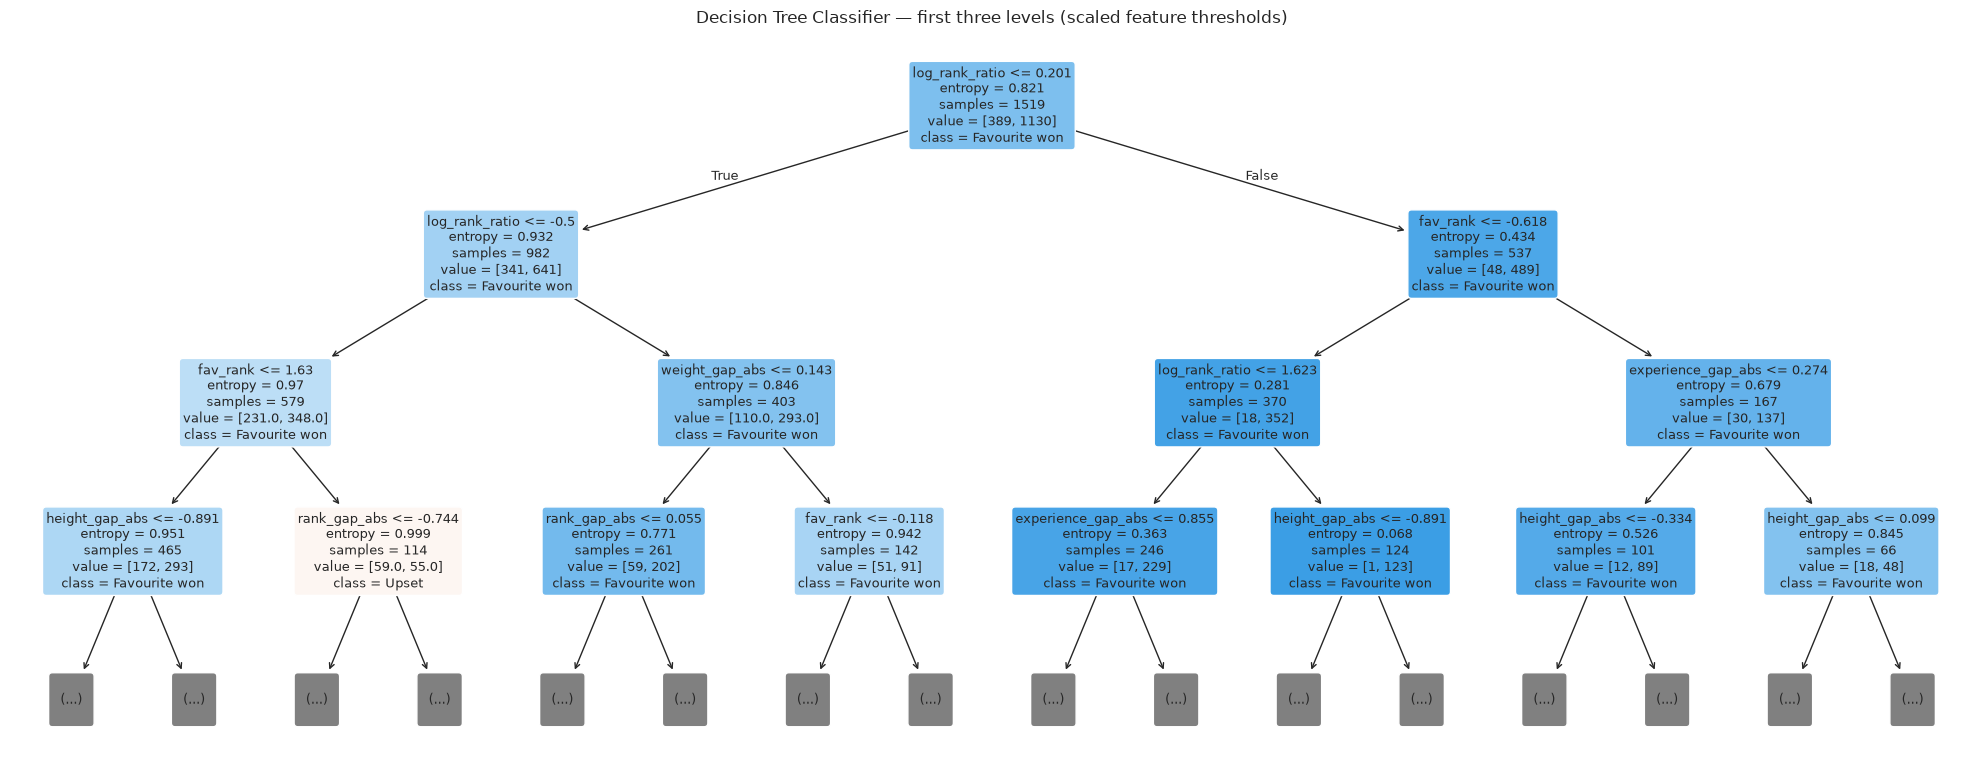

In [15]:
tree = train_and_evaluate(
    "Decision Tree", "A",
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    {
        "model__max_depth": [2, 3, 4, 5, 7, 10],
        "model__min_samples_leaf": [1, 5, 20],
        "model__criterion": ["gini", "entropy"],
    },
)

plt.figure(figsize=(20, 8))
plot_tree(
    tree.named_steps["model"], feature_names=FEATURES, class_names=["Upset", "Favourite won"],
    filled=True, rounded=True, max_depth=3, fontsize=9,
)
plt.title("Decision Tree Classifier — first three levels (scaled feature thresholds)")
plt.tight_layout()
plt.show()

The root split is on `log_rank_ratio`, and the next level splits on `fav_rank`. This confirms that relative ranking is the most informative pre-match variable. The thresholds are on the standardised scale.

### Algorithm 5 — Support Vector Machine (SVC)
We tune the regularisation strength `C` and the kernel. Features are scaled because the margin depends on distances.

In [16]:
svc = train_and_evaluate(
    "Support Vector Machine", "A",
    SVC(probability=True, random_state=RANDOM_STATE),
    {"model__C": [0.1, 1, 10], "model__kernel": ["linear", "rbf"]},
)

Support Vector Machine — best parameters: {'model__C': 10, 'model__kernel': 'rbf'}
CV f1_weighted: 0.6621


,Accuracy,Precision,Recall,F1,ROC-AUC
Support Vector Machine,0.7526,0.7183,0.7526,0.6777,0.6396


## 6. Classification Part B (Review 2 algorithms)

All five Part-B models use **exactly the same dataset, features, preprocessing and train/test split** as Part A (rubric A1).

### Algorithm 6 — Random Forest
An ensemble of de-correlated trees. We tune `n_estimators` and `max_depth`, then look at feature importance.

Random Forest — best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
CV f1_weighted: 0.6906


,Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest,0.7342,0.6828,0.7342,0.6862,0.6549


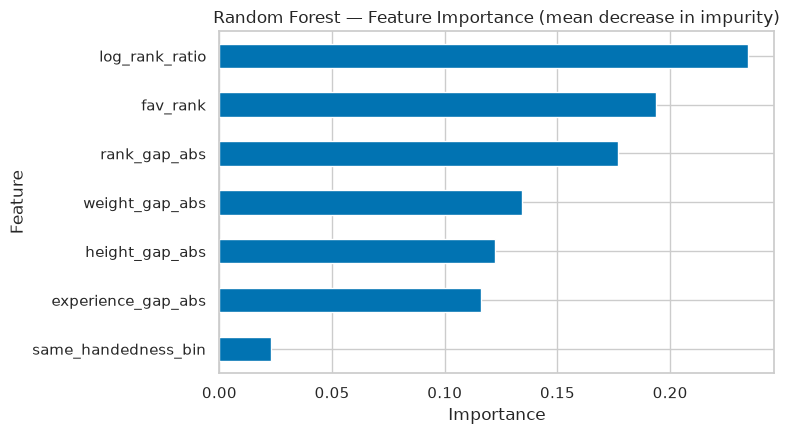

In [17]:
rf = train_and_evaluate(
    "Random Forest", "B",
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    {"model__n_estimators": [100, 300], "model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 10]},
)

importance = pd.Series(rf.named_steps["model"].feature_importances_, index=FEATURES).sort_values()
plt.figure(figsize=(8, 4.5))
importance.plot(kind="barh", color=sns.color_palette("colorblind")[0])
plt.title("Random Forest — Feature Importance (mean decrease in impurity)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

The two ranking features added in Review 2, `log_rank_ratio` and `fav_rank`, are the two most important features. Handedness contributes almost nothing.

### Algorithm 7 — AdaBoost
AdaBoost trains weak learners one after another, giving more weight each time to the matches the previous learners got wrong. `n_estimators` and `learning_rate` trade off against each other.

In [18]:
ada = train_and_evaluate(
    "AdaBoost", "B",
    AdaBoostClassifier(random_state=RANDOM_STATE),
    {"model__n_estimators": [50, 100, 200], "model__learning_rate": [0.05, 0.1, 0.5, 1.0]},
)

AdaBoost — best parameters: {'model__learning_rate': 1.0, 'model__n_estimators': 200}
CV f1_weighted: 0.6701


,Accuracy,Precision,Recall,F1,ROC-AUC
AdaBoost,0.7342,0.6718,0.7342,0.6723,0.6702


### Algorithm 8 — Gradient Boosting
Each new tree is fitted to the gradient of the current ensemble's log-loss. Shallow trees with a small learning rate usually generalise best.

In [19]:
gb = train_and_evaluate(
    "Gradient Boosting", "B",
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    {"model__n_estimators": [100, 200], "model__learning_rate": [0.01, 0.05, 0.1], "model__max_depth": [2, 3]},
)

Gradient Boosting — best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
CV f1_weighted: 0.6724


,Accuracy,Precision,Recall,F1,ROC-AUC
Gradient Boosting,0.7184,0.658,0.7184,0.6702,0.6533


### Algorithm 9 — Bagging (Decision Tree base estimator)
Bagging trains many trees on bootstrap samples and averages their votes. This reduces the variance of a single tree.

In [20]:
bag = train_and_evaluate(
    "Bagging", "B",
    BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                      random_state=RANDOM_STATE, n_jobs=-1),
    {"model__n_estimators": [50, 100, 200], "model__max_samples": [0.5, 1.0]},
)

Bagging — best parameters: {'model__max_samples': 1.0, 'model__n_estimators': 100}
CV f1_weighted: 0.7029


,Accuracy,Precision,Recall,F1,ROC-AUC
Bagging,0.7105,0.6554,0.7105,0.6697,0.6345


### Algorithm 10 — MLP Classifier (Neural Network)
We tune the hidden-layer architecture and the activation function. Early stopping protects against over-fitting on this small dataset.

In [21]:
mlp = train_and_evaluate(
    "MLP Neural Network", "B",
    MLPClassifier(max_iter=1000, early_stopping=True, random_state=RANDOM_STATE),
    {"model__hidden_layer_sizes": [(16,), (32, 16), (64, 32)], "model__activation": ["relu", "tanh"],
     "model__alpha": [1e-4, 1e-2]},
)

MLP Neural Network — best parameters: {'model__activation': 'tanh', 'model__alpha': 0.01, 'model__hidden_layer_sizes': (16,)}
CV f1_weighted: 0.6821


,Accuracy,Precision,Recall,F1,ROC-AUC
MLP Neural Network,0.7579,0.7374,0.7579,0.6846,0.7041


## 7. Consolidated 10-algorithm comparison table (rubric A2)

All ten models are evaluated on the **same 380-match held-out test set**. For context we add a majority-class baseline that always predicts "favourite wins". Models are ranked by weighted F1, the tuning metric.

In [22]:
baseline_pred = np.ones_like(y_test)
baseline_row = compute_metrics(y_test, baseline_pred, np.full(len(y_test), y_train.mean()))

comparison_df = (
    pd.DataFrame(results).T
    .drop(columns="Best params")
    .astype({m: float for m in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]})
    .sort_values(["F1", "ROC-AUC"], ascending=False)
)
comparison_df.insert(0, "Rank", range(1, len(comparison_df) + 1))

display(
    comparison_df.style
    .format({m: "{:.4f}" for m in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]})
    .highlight_max(subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"], color="#c6e9c3")
)
print("Majority-class baseline:", {k: round(v, 4) for k, v in baseline_row.items()})

,Rank,Part,Accuracy,Precision,Recall,F1,ROC-AUC
Gaussian Naive Bayes,1,A,0.7368,0.7232,0.7368,0.7286,0.6961
Random Forest,2,B,0.7342,0.6828,0.7342,0.6862,0.6549
MLP Neural Network,3,B,0.7579,0.7374,0.7579,0.6846,0.7041
Support Vector Machine,4,A,0.7526,0.7183,0.7526,0.6777,0.6396
AdaBoost,5,B,0.7342,0.6718,0.7342,0.6723,0.6702
Gradient Boosting,6,B,0.7184,0.6580,0.7184,0.6702,0.6533
Bagging,7,B,0.7105,0.6554,0.7105,0.6697,0.6345
Logistic Regression,8,A,0.7526,0.7434,0.7526,0.6626,0.7046
Decision Tree,9,A,0.7395,0.6649,0.7395,0.6549,0.6652
K-Nearest Neighbors,10,A,0.6947,0.6351,0.6947,0.6541,0.6002


Majority-class baseline: {'Accuracy': 0.7447, 'Precision': 0.5546, 'Recall': 0.7447, 'F1': 0.6358, 'ROC-AUC': 0.5}


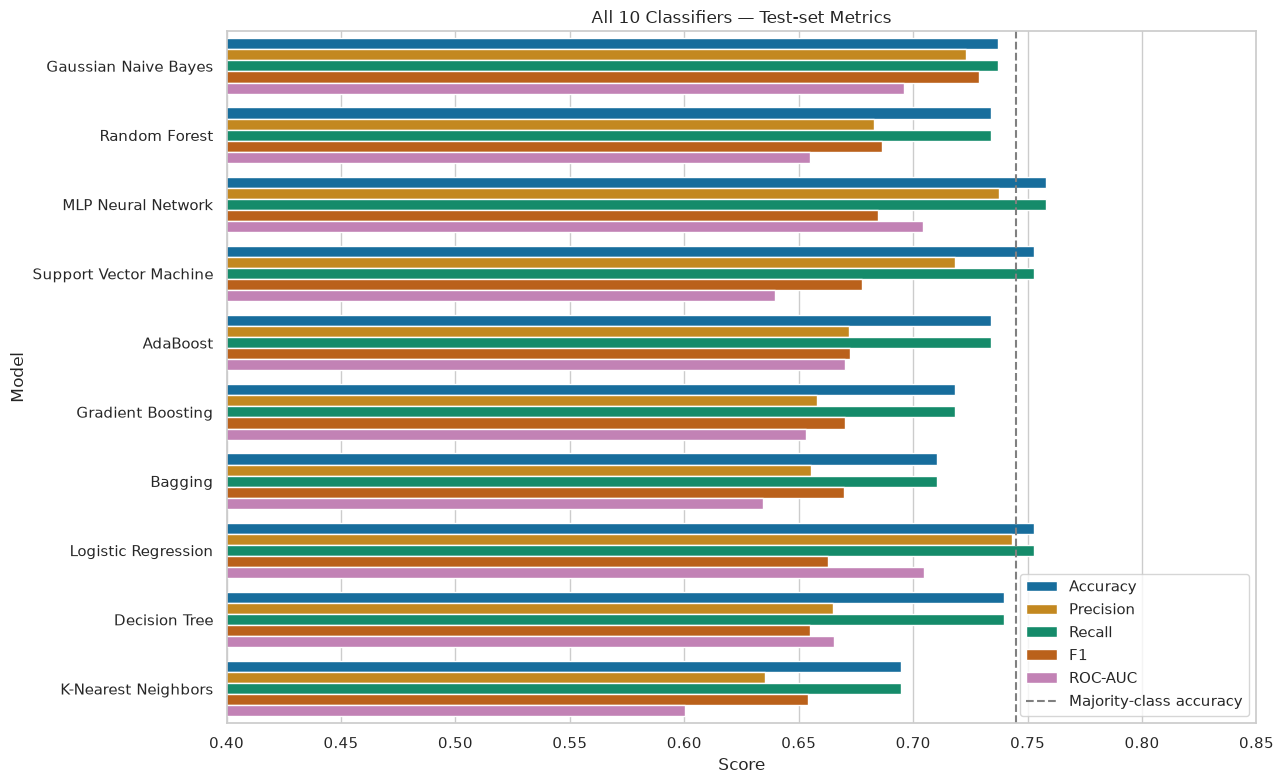

In [23]:
plot_data = comparison_df.reset_index(names="Model").melt(
    id_vars=["Model", "Part"], value_vars=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    var_name="Metric", value_name="Score",
)

plt.figure(figsize=(13, 8))
sns.barplot(data=plot_data, y="Model", x="Score", hue="Metric", palette="colorblind")
plt.axvline(baseline_row["Accuracy"], color="grey", linestyle="--", label="Majority-class accuracy")
plt.title("All 10 Classifiers — Test-set Metrics")
plt.xlabel("Score")
plt.ylabel("Model")
plt.xlim(0.4, 0.85)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. Confusion matrices and ROC curves for all algorithms

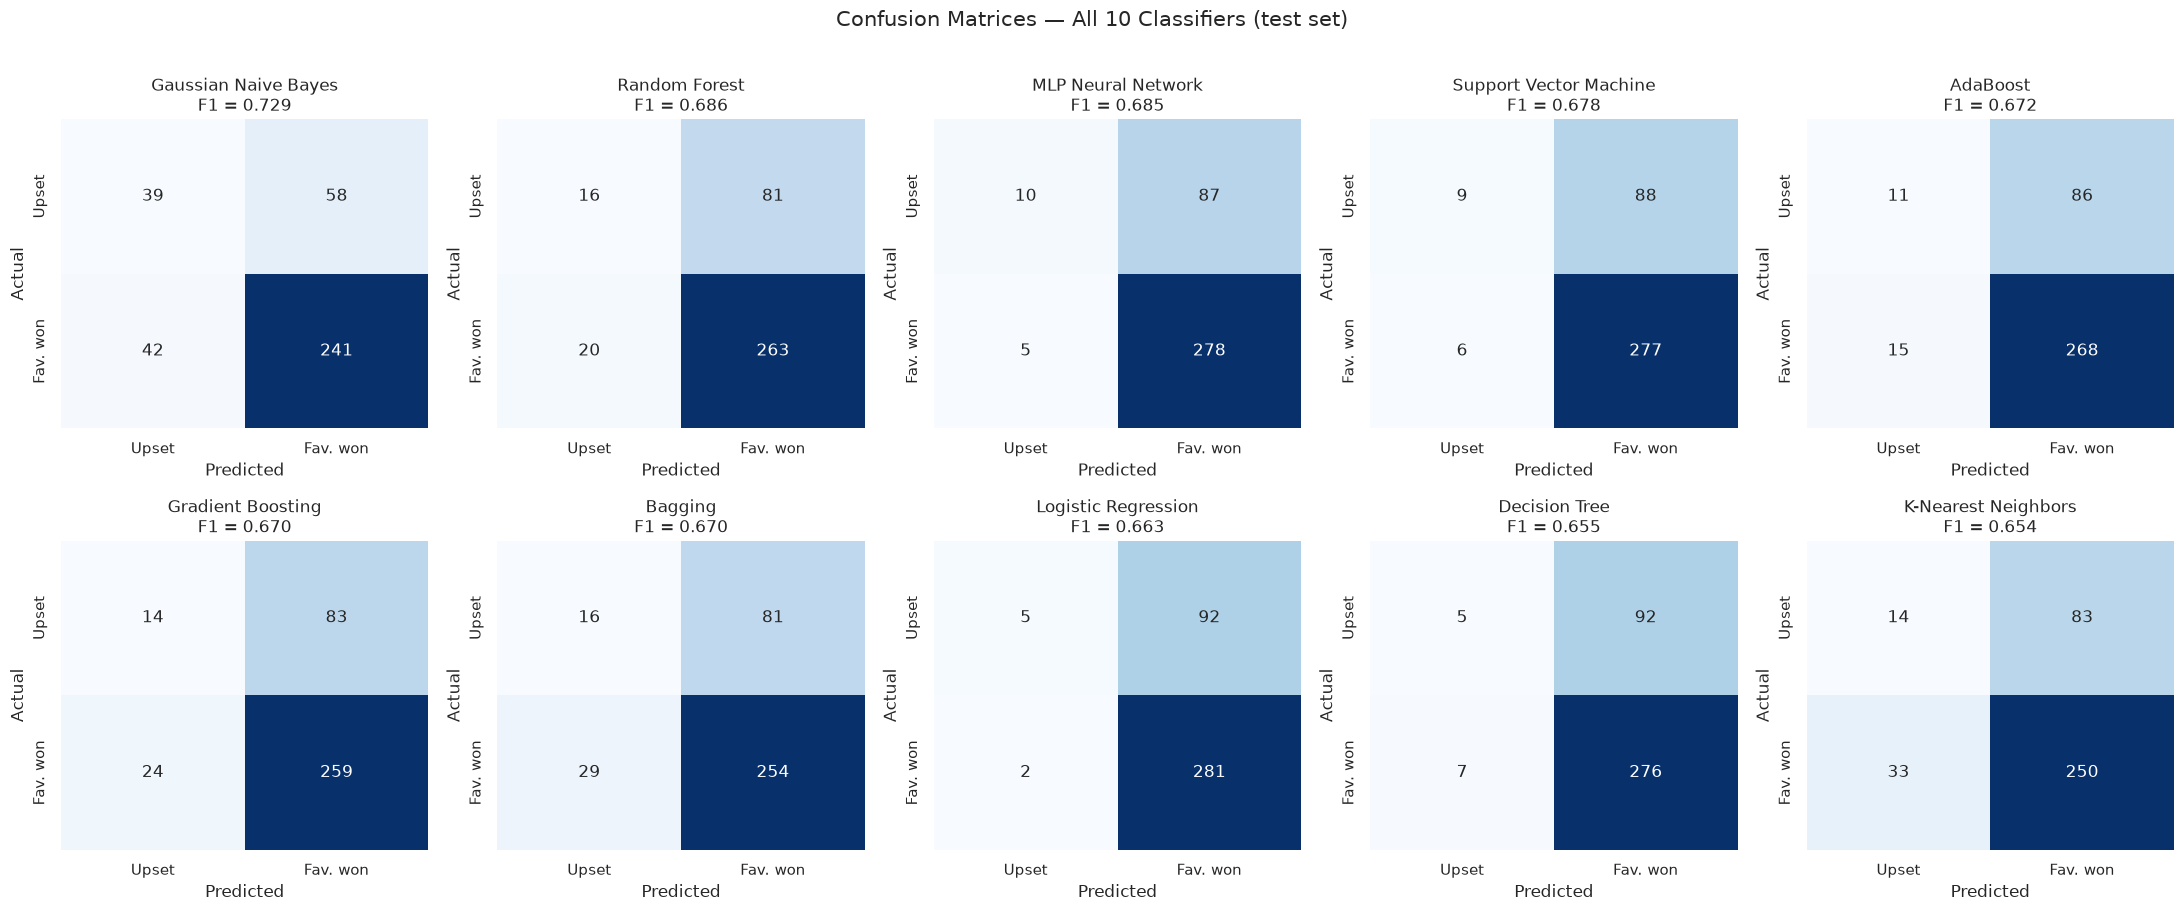

In [24]:
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, name in zip(axes.ravel(), comparison_df.index):
    cm = confusion_matrix(y_test, predictions[name][0])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Upset", "Fav. won"], yticklabels=["Upset", "Fav. won"])
    ax.set_title(f"{name}\nF1 = {comparison_df.loc[name, 'F1']:.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.suptitle("Confusion Matrices — All 10 Classifiers (test set)", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

**Confusion-matrix observations.** Every model gets most favourite wins right. Where they differ is in how many **upsets** (top-left cell) they catch. Logistic Regression and the MLP have the highest accuracy because they predict almost every match as a favourite win, which brings them close to the majority-class baseline. Weighted F1 penalises this, which is why we rank by it.

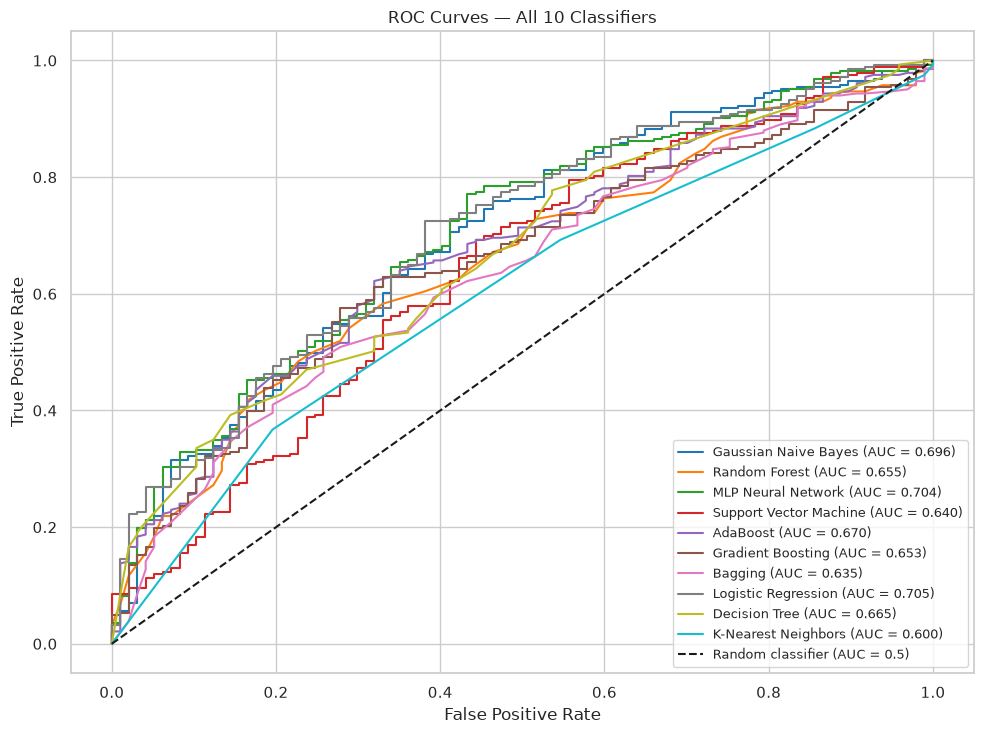

In [25]:
plt.figure(figsize=(10, 7.5))
colors = sns.color_palette("tab10", len(comparison_df))
for color, name in zip(colors, comparison_df.index):
    fpr, tpr, _ = roc_curve(y_test, predictions[name][1])
    plt.plot(fpr, tpr, color=color, label=f"{name} (AUC = {comparison_df.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier (AUC = 0.5)")
plt.title("ROC Curves — All 10 Classifiers")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**ROC observations.** Every model is clearly above the diagonal. Predicting tennis upsets from rankings and physical attributes alone is noisy, because form, injuries and surface are not in the data. AUC values of about 0.60–0.70 are therefore realistic and do not mean the models failed. Logistic Regression, the MLP and Gaussian Naive Bayes rank matches best (AUC ≈ 0.70).

## 9. Final model selection (rubric A3)

### 9.1 5-fold cross-validation of the two best models
The test set is a single sample of 380 matches, so we re-check the top two models with stratified 5-fold cross-validation on the full modelling data.

In [26]:
top_two = comparison_df.index[:2].tolist()

cv_rows = []
for name in top_two:
    scores = cross_validate(clone(fitted_models[name]), X, y, cv=CV, n_jobs=-1,
                            scoring=["accuracy", "f1_weighted", "roc_auc"])
    cv_rows.append({
        "Model": name,
        "CV Accuracy": f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
        "CV weighted F1": f"{scores['test_f1_weighted'].mean():.4f} ± {scores['test_f1_weighted'].std():.4f}",
        "CV ROC-AUC": f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
    })
display(pd.DataFrame(cv_rows).set_index("Model"))

,CV Accuracy,CV weighted F1,CV ROC-AUC
Model,,,
Gaussian Naive Bayes,0.7093 ± 0.0201,0.6989 ± 0.0146,0.6883 ± 0.0371
Random Forest,0.7214 ± 0.0094,0.6846 ± 0.0091,0.6777 ± 0.0209


### 9.2 Documented improvement from tuning and feature engineering

For the selected model, we compare three configurations on the same test set:
1. **Default hyperparameters**, Review 1 feature set
2. **Default hyperparameters**, Review 2 feature set (adds `fav_rank` and `log_rank_ratio`)
3. **GridSearchCV-tuned hyperparameters**, Review 2 feature set (the final model)

In [27]:
best_name = comparison_df.index[0]
best_model = fitted_models[best_name]


def evaluate_pipeline(estimator, features):
    pipe = Pipeline([("preprocess", make_preprocessor(features)), ("model", estimator)])
    pipe.fit(X_train[features], y_train)
    return compute_metrics(y_test, pipe.predict(X_test[features]), pipe.predict_proba(X_test[features])[:, 1])


# Same algorithm with scikit-learn's default hyperparameters (only reproducibility/compatibility settings kept)
tuned_estimator = best_model.named_steps["model"]
default_model = type(tuned_estimator)()
fixed_settings = {"random_state": RANDOM_STATE, "probability": True, "max_iter": 2000,
                  "estimator": DecisionTreeClassifier(random_state=RANDOM_STATE)}
default_model.set_params(**{k: v for k, v in fixed_settings.items() if k in default_model.get_params()})

improvement_df = pd.DataFrame({
    "1. Default params, Review 1 features": evaluate_pipeline(clone(default_model), REVIEW1_FEATURES),
    "2. Default params, Review 2 features": evaluate_pipeline(clone(default_model), FEATURES),
    "3. Tuned params, Review 2 features (final)": {k: results[best_name][k] for k in
                                                   ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]},
}).T

print(f"Selected model: {best_name}")
print("Tuned hyperparameters:", results[best_name]["Best params"])
display(improvement_df.style.format("{:.4f}"))

gain = improvement_df.iloc[-1] - improvement_df.iloc[0]
print("\nImprovement of final model over default/Review 1 configuration:")
display(gain.to_frame("change").T.style.format("{:+.4f}"))

Selected model: Gaussian Naive Bayes
Tuned hyperparameters: {'model__var_smoothing': np.float64(0.01)}


,Accuracy,Precision,Recall,F1,ROC-AUC
"1. Default params, Review 1 features",0.7158,0.5849,0.7158,0.6297,0.5725
"2. Default params, Review 2 features",0.7342,0.7212,0.7342,0.7265,0.6964
"3. Tuned params, Review 2 features (final)",0.7368,0.7232,0.7368,0.7286,0.6961



Improvement of final model over default/Review 1 configuration:


,Accuracy,Precision,Recall,F1,ROC-AUC
change,+0.0211,+0.1382,+0.0211,+0.0989,+0.1237


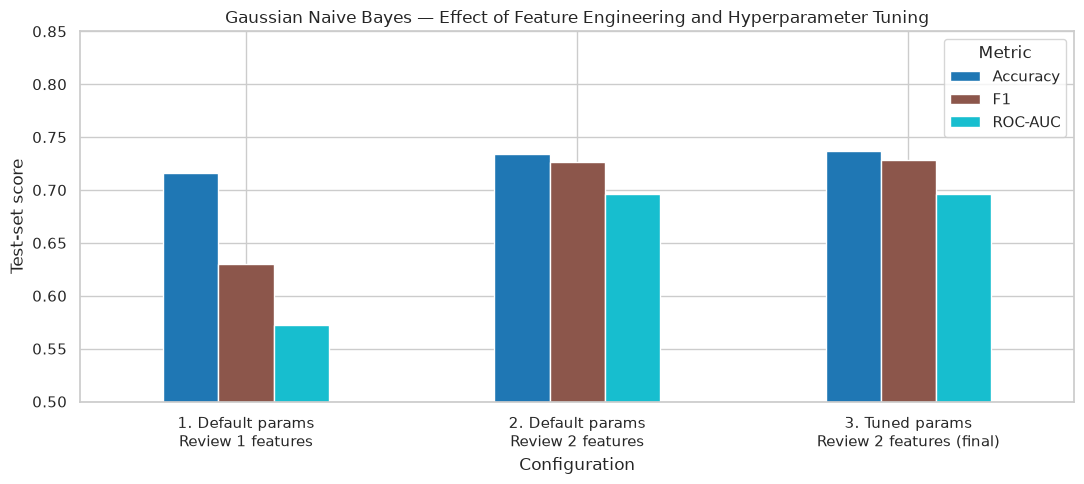

In [28]:
ax = improvement_df[["Accuracy", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(11, 5), rot=0, colormap="tab10")
ax.set_title(f"{best_name} — Effect of Feature Engineering and Hyperparameter Tuning")
ax.set_xlabel("Configuration")
ax.set_ylabel("Test-set score")
ax.set_ylim(0.5, 0.85)
ax.set_xticklabels([t.get_text().replace(", ", "\n") for t in ax.get_xticklabels()])
ax.legend(title="Metric")
plt.tight_layout()
plt.show()

**Final model: Gaussian Naive Bayes** (`var_smoothing = 0.01`).

**Why this model:**
- **Highest weighted F1 on the test set (0.729)** and the **highest 5-fold CV weighted F1 (0.699 ± 0.015)**, so its lead is not an artefact of one split.
- It catches far more **upsets** than the other models. The MLP and Logistic Regression have slightly higher accuracy and ROC-AUC (≈ 0.70), but they get there by predicting almost every match as a favourite win.
- Its ROC-AUC (0.696) is within 0.01 of the best model, so it gives up very little ranking quality.
- It trains in milliseconds and its probabilities are easy to explain, which suits the interactive GUI.

**Documented improvement (same test set):**

| Configuration | Accuracy | weighted F1 | ROC-AUC |
|---|---:|---:|---:|
| Default params, Review 1 features | 0.716 | 0.630 | 0.573 |
| Default params, Review 2 features | 0.734 | 0.727 | 0.696 |
| **Tuned params, Review 2 features (final)** | **0.737** | **0.729** | **0.696** |
| *Change vs. Review 1 configuration* | *+0.021* | ***+0.099*** | ***+0.124*** |

Most of the gain comes from the two engineered rank features. Tuning `var_smoothing` adds a small further gain in accuracy and F1.

## 10. Summary and conclusions

| Rank | Model | Part | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---:|---|:---:|---:|---:|---:|---:|---:|
| 1 | Gaussian Naive Bayes | A | 0.7368 | 0.7232 | 0.7368 | **0.7286** | 0.6961 |
| 2 | Random Forest | B | 0.7342 | 0.6828 | 0.7342 | 0.6862 | 0.6549 |
| 3 | MLP Neural Network | B | **0.7579** | 0.7374 | **0.7579** | 0.6846 | 0.7041 |
| 4 | Support Vector Machine | A | 0.7526 | 0.7183 | 0.7526 | 0.6777 | 0.6396 |
| 5 | AdaBoost | B | 0.7342 | 0.6718 | 0.7342 | 0.6723 | 0.6702 |
| 6 | Gradient Boosting | B | 0.7184 | 0.6580 | 0.7184 | 0.6702 | 0.6533 |
| 7 | Bagging | B | 0.7105 | 0.6554 | 0.7105 | 0.6697 | 0.6345 |
| 8 | Logistic Regression | A | 0.7526 | **0.7434** | 0.7526 | 0.6626 | **0.7046** |
| 9 | Decision Tree | A | 0.7395 | 0.6649 | 0.7395 | 0.6549 | 0.6652 |
| 10 | K-Nearest Neighbors | A | 0.6947 | 0.6351 | 0.6947 | 0.6541 | 0.6002 |
| – | *Majority-class baseline* | – | 0.7447 | 0.5546 | 0.7447 | 0.6358 | 0.5000 |

**Key takeaways**
1. **Leakage fixed:** the winner/loser-specific columns (`WRank`, `LRank`, `rank_diff`) are never used directly. Every feature is symmetric in the two players.
2. **Rankings matter most:** `log_rank_ratio` is the top feature in the Decision Tree root split, the Random Forest importances and the Logistic Regression odds ratios (OR ≈ 2.4 per SD).
3. **Ensembles did not help here:** with seven features and a noisy outcome, Random Forest, boosting and bagging did not beat the simpler probabilistic models. The extra flexibility mostly fitted noise.
4. **Limitations:** current form, injuries, head-to-head records and the betting market are not in the data, which caps achievable performance at roughly AUC ≈ 0.70.

### Review 2 checklist
- [x] A1 — All 5 Part-B algorithms trained on the same dataset, features and split as Part A, with no errors
- [x] A2 — Single consolidated table of all 10 algorithms (Accuracy, Precision, Recall, F1, ROC-AUC)
- [x] A3 — Best model selected with justification, tuning applied (GridSearchCV for all 10 models), improvement documented
- [x] Confusion matrices and ROC curves for all 10 models; 5-fold CV for the two best models
- [x] Pre-processing fitted on training data only (Pipelines), `random_state = 42` everywhere